# Laser Filamentation: Nonlinear Self-Channeling of Light
**PHY204 — Project P# 17**  
*Mayad MNIF, Don Van BEUSICHEM, Nayl POIROT, Marc OBEID*

---

## Abstract

This notebook implements the cylindrically symmetric numerical solver of femtosecond laser
filamentation in fused silica at 800 nm that accompanies our project report. The model is a
generalised nonlinear Schrödinger equation coupled to a Drude plasma rate equation, integrated by
a Strang operator-splitting scheme combining spectral group-velocity dispersion, Crank–Nicolson
radial diffraction, and pointwise nonlinear updates. The full physics run produces the canonical
filamentation signatures: Kerr self-focusing, plasma-mediated intensity clamping at
$\sim\!10^{13}$ W/cm², dynamic-replenishment pulse splitting, and an angular spectrum that aligns
with the analytic X-wave hyperbolae of normal-GVD conical waves.

## Notebook layout

1. **Imports and material parameters** (cells 1–3) — set up Python, load NumPy/SciPy/Matplotlib, define the silica parameter dictionary.
2. **Derived quantities** (cell 5) — compute critical power $P_{cr}$, Marburger collapse distance $z_{\rm Marburger}$, Rayleigh range $z_R$, dispersion length $L_D$, plasma critical density $\rho_c$.
3. **The `Filament` class and `propagate` driver** (cells 7–8) — the solver itself.
4. **Validation tests A–D** (cells 10–13) — verify each physical effect against an analytic limit.
5. **Main run** (cell 15) at $P_{\rm in} = 5\,P_{cr}$ over $L_z = 12$ mm with 12 snapshots.
6. **Diagnostics and figures** (cells 16–28) — the eight figures used in the report.
7. **Discussion and summary** (cell 29).

The full report `laser_filamentation_report.tex` (and PDF) accompanies this notebook in the same folder. Equation derivations, parameter tables and bibliography live in the report; the notebook contains the executable model and the diagnostics that produce the report's figures.

## Governing equations (V1.5)

Scalar envelope $E(r,\tau,z)$ in cylindrical symmetry, retarded frame $\tau = t - z/v_g$:

$$
\partial_z E \;=\; \underbrace{\frac{i}{2k}\!\left(\partial_r^2+\tfrac{1}{r}\partial_r\right)\!E}_{\text{diffraction}}
\;\underbrace{-\,\frac{i k''}{2}\,\partial_\tau^2 E}_{\text{GVD}}
\;\underbrace{+\,i k_0 n_2 |E|^2 E}_{\text{Kerr}}
\;\underbrace{-\,\tfrac{\beta_K}{2}|E|^{2K-2}E}_{\text{MPA}}
\;\underbrace{-\,\tfrac{\sigma}{2}(1+i\omega_0\tau_c)\,\rho E}_{\text{Drude plasma (absorption + defocusing)}}
$$

$$
\partial_\tau \rho \;=\; \underbrace{\sigma_K|E|^{2K}(\rho_{nt}-\rho)}_{\text{multiphoton ionisation}}
\;+\;\underbrace{\tfrac{\sigma}{U_i}\rho|E|^2}_{\text{avalanche}}
\;-\;\underbrace{a\,\rho^2}_{\text{recombination}}
$$

**Convention:** $|E|^2 = I$ in W/m² (Couairon/Mysyrowicz convention).

**V1.5 model — what is included:** radial diffraction, normal GVD, instantaneous Kerr, multiphoton absorption ($K=5$ for silica at 800 nm), multiphoton ionisation, plasma defocusing, plasma absorption (real part of the Drude response), avalanche ionisation, radiative recombination.

**Not included (extensions for V2):** delayed Raman response, self-steepening, space-time focusing, vector / polarisation effects, transverse $(x,y)$ symmetry breaking. See the conclusion of the report for the V2 priority list.

## How to run

Run cells top to bottom. The validation tests (A–D) take a few seconds each. The main 12-mm propagation cell takes approximately 5 minutes on a laptop CPU. Total notebook runtime is around 8–10 minutes. All figures are saved to `figures/` for direct inclusion in the LaTeX report.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve
from scipy.constants import c as c0, epsilon_0, m_e, e as q_e

np.set_printoptions(precision=4, suppress=True)

## Material parameters (fused silica at 800 nm)

The cell below collects the model parameters into a single dictionary that is passed unchanged to the `Filament` class. We follow the SI convention throughout to avoid the unit-conversion errors that are the most common source of bugs in filamentation codes; literature values quoted in cm-based units are converted to SI in one place with inline comments.

The values are taken from the practitioner-guide compilation of Couairon & Kolesik (Eur. Phys. J. Special Topics **199**, 5–76 (2011)).

### Linear and Kerr parameters

| Symbol | Meaning | Value | Units |
|---|---|---|---|
| $\lambda_0$ | carrier wavelength | $800$ | nm |
| $n_0$ | linear refractive index | $1.453$ | — |
| $n_2$ | Kerr coefficient | $3.2\times 10^{-20}$ | m²/W |
| $k''$ | group-velocity dispersion | $3.61\times 10^{-26}$ | s²/m |

### Multiphoton / plasma parameters

| Symbol | Meaning | Value | Units |
|---|---|---|---|
| $K$ | photons per ionisation event | $5$ | — |
| $U_i$ | ionisation potential of silica | $9$ | eV |
| $\beta_K$ | $K$-photon absorption coefficient | $1.3\times 10^{-64}$ | m⁷/W⁴ |
| $\sigma_K$ | MPI rate coefficient | $1.3\times 10^{-75}$ | m¹⁰/(W⁵·s) |
| $\sigma$ | inverse-bremsstrahlung cross-section | $2.78\times 10^{-24}$ | m² |
| $\tau_c$ | electron collision time | $1.27$ | fs |
| $\rho_{nt}$ | neutral molecule density of SiO₂ | $2.1\times 10^{28}$ | m⁻³ |
| $a$ | radiative recombination coefficient | $7\times 10^{-19}$ | m³/s |
| $\rho_c$ | critical Drude plasma density at $\omega_0$ | $1.74\times 10^{27}$ | m⁻³ |

### Pulse and grid parameters

| Symbol | Meaning | Value |
|---|---|---|
| $w_0$ | input beam half-width | $50\,\mu$m |
| $\tau_p$ | input pulse $1/e$ field half-width | $85$ fs |
| $P_{\rm in}/P_{cr}$ | input power in critical-power units | $5$ |
| $L_z$ | propagation length | $12$ mm |
| $\Delta z$ | longitudinal step | $3\,\mu$m |
| $N_r,\,R_{\max}$ | radial grid points, box | $384,\,400\,\mu$m |
| $N_\tau,\,\tau_{\max}$ | temporal grid points, half-box | $512,\,500$ fs |

These choices give $\Delta r \approx 1.04\,\mu$m (a few grid points across the few-µm filament core), $\Delta \tau \approx 1.95$ fs (much shorter than the plasma rise time), and a per-step nonlinear phase $k_0 n_2 I_{\rm peak} \Delta z \lesssim 0.1$ rad in the clamped state — well below the linearisation limit of the split-step scheme.

In [23]:
# --- Silica parameters at lambda0 = 800 nm (Couairon-Mysyrowicz practitioner guide) ---
params = dict(
    lambda0 = 800e-9,           # carrier wavelength [m]
    n0      = 1.453,            # linear refractive index
    n2      = 3.2e-20,          # Kerr coefficient [m^2 / W]
    kpp     = 3.61e-26,         # k''(omega0) group-velocity dispersion [s^2 / m]  (normal: +)
    K       = 5,                # number of photons in MPI/MPA for silica @ 800 nm
    # beta_K in SI: units of m^(2K-3) / W^(K-1) = m^7 / W^4 for K=5.
    # Typical literature value: beta_K ~ 1.3e-50 cm^7/W^4  =>  SI = 1.3e-50 * 1e-14.
    # (1 cm^7 = (1e-2 m)^7 = 1e-14 m^7)
    beta_K  = 1.3e-50 * 1e-14,  # m^7 / W^4
    # sigma_K in (cm^2/W)^K * 1/s * cm^(2K-3)... we just use the classical
    # convention: sigma_K_SI [m^(2K) / (W^K s)] converted from cm-based value
    # sigma_K(silica) ~ 1.3e-55 cm^{2K} s^-1 (cm^2/W)^K  => SI factor (1e-2 m/cm)^(2K) = 1e-20 for K=5
    sigma_K = 1.3e-55 * 1e-20,  # m^10 / (W^5 * s)
    rho_nt  = 2.1e28,           # neutral density of SiO2 [1/m^3]  (~ 2.1e22 / cm^3)
)

# Drude critical density at carrier frequency
omega0 = 2 * np.pi * c0 / params["lambda0"]
params["omega0"] = omega0
params["rho_c"] = m_e * epsilon_0 * omega0**2 / q_e**2     # ~ 1.74e27 /m^3

# Pulse parameters - chosen ~5x critical power, 85 fs (~ 100 fs FWHM).
# w0 = 50 um and L = 6 mm are chosen so that the Marburger collapse distance
# z_c ~ 3.8 mm falls well within the propagation length, letting us see both
# collapse and the post-collapse plasma-clamped state in a first run.
params.update(
    w0          = 50e-6,        # beam waist (1/e field radius) [m]
    tau_p       = 85e-15,       # pulse duration (1/e field half-width) [s]
    P_over_Pcr  = 5.0,          # ratio of peak power to critical power
    R_max       = 400e-6,       # radial box [m]
    Nr          = 384,          # radial grid points (bumped from 256 for cleaner core)
    tau_max     = 500e-15,      # half-width of temporal box [s]
    Ntau        = 512,
    dz          = 3e-6,         # longitudinal step [m]
    z_max       = 12e-3,        # total propagation length [m]
    absorber_frac = 0.08,       # fraction of radial box occupied by absorber
)

# --- Drude plasma response (V1.5: avalanche, recombination, plasma absorption) ---
# Values for fused silica at 800 nm from Couairon practitioner guide.
# tau_c        : electron momentum relaxation (collision) time
# sigma_inv_brem: inverse-bremsstrahlung cross-section (couples plasma to field
#                  for both absorption AND defocusing through the Drude model)
# U_i          : ionisation potential / band gap; sets photon-energy normalisation
#                  for the avalanche source term
# recomb_coef  : radiative-recombination coefficient (the "a" in -a*rho^2 in the
#                  rate equation); negligible during the pulse but set for completeness
params.update(
    tau_c          = 1.27e-15,        # [s]
    sigma_inv_brem = 2.78e-24,        # [m^2]
    U_i            = 9.0 * q_e,       # [J]  (~ 9 eV)
    recomb_coef    = 7e-19,           # [m^3 / s]
)

## Derived quantities (sanity check before running)

The cell below computes a handful of dimensional quantities derived from the parameter dictionary above. They serve as sanity checks: the printed numbers should match the expected order of magnitude before any non-trivial physics run.

| Quantity | Formula | Physical meaning |
|---|---|---|
| Critical power | $P_{cr} = \lambda_0^2 / (2\pi n_0 n_2)$ | threshold above which Kerr self-focusing overcomes diffraction |
| Peak input intensity | $I_0 = 2 P_{\rm in} / (\pi w_0^2)$ | on-axis intensity of a Gaussian beam |
| Rayleigh length | $z_R = \pi n_0 w_0^2 / \lambda_0$ | linear-diffraction length scale |
| Marburger collapse | $z_c = 0.367\, z_R / \sqrt{(\sqrt{P_{\rm in}/P_{cr}} - 0.852)^2 - 0.0219}$ | semi-empirical self-focusing collapse distance for a Gaussian beam |
| Dispersion length | $L_D = \tau_p^2 / |k''|$ | distance over which GVD doubles the pulse duration |
| Critical density | $\rho_c = m_e \varepsilon_0 \omega_0^2 / e^2$ | electron density at which the plasma frequency equals the laser frequency |

Expected values for our working point ($P_{\rm in} = 5\,P_{cr}$, $w_0 = 50\,\mu$m, $\tau_p = 85$ fs in fused silica at 800 nm):
- $P_{cr} \approx 2.2$ MW, so $P_{\rm in} \approx 11$ MW;
- $I_0 \approx 2.8\times 10^{11}$ W/cm²;
- $z_R \approx 14.3$ mm — the linear-diffraction length is about twice the propagation box;
- $z_c \approx 3.8$ mm — Kerr collapse predicted to occur about a third of the way through the box;
- $L_D \approx 200$ mm — dispersion is essentially negligible on our 12 mm propagation length;
- $\rho_c \approx 1.74\times 10^{21}$ /cm³ — a hard upper bound the plasma density should never approach.

In [29]:
p = params  # alias
P_cr = p["lambda0"]**2 / (2 * np.pi * p["n0"] * p["n2"])
P_peak = p["P_over_Pcr"] * P_cr
I0 = 2 * P_peak / (np.pi * p["w0"]**2)
A0 = np.sqrt(I0)                                   # |A|^2 = I convention
z_R = np.pi * p["n0"] * p["w0"]**2 / p["lambda0"]
# Marburger
ratio = p["P_over_Pcr"]
disc = (np.sqrt(ratio) - 0.852)**2 - 0.0219
z_Mar = 0.367 * z_R / np.sqrt(disc) if disc > 0 else np.nan
L_D = p["tau_p"]**2 / abs(p["kpp"])

print(f"Critical power  P_cr          = {P_cr*1e-6:8.3f} MW")
print(f"Peak power      P             = {P_peak*1e-6:8.3f} MW  ({ratio:.2f} P_cr)")
print(f"Peak intensity  I0            = {I0*1e-4:8.3e} W/cm^2")
print(f"Peak amplitude  A0 = sqrt(I0) = {A0:8.3e} sqrt(W/m^2)")
print(f"Rayleigh length z_R           = {z_R*1e3:8.3f} mm")
print(f"Marburger zc                  = {z_Mar*1e3:8.3f} mm")
print(f"Dispersion length L_D         = {L_D*1e3:8.3f} mm")
print(f"Neutral density rho_nt        = {p['rho_nt']:.3e} 1/m^3")
print(f"Critical density rho_c        = {p['rho_c']:.3e} 1/m^3")

# Drude plasma response (V1.5: avalanche, recombination, plasma absorption)
print()
print(f"Collision time tau_c          = {p['tau_c']*1e15:8.3f} fs")
print(f"omega0 * tau_c                = {p['omega0']*p['tau_c']:8.3f}      (ratio sets defocus/abs balance)")
print(f"Inv-bremsstr. cross-section   = {p['sigma_inv_brem']*1e4:8.3e} cm^2")
print(f"Ionisation potential U_i      = {p['U_i']/q_e:8.3f} eV")
print(f"Recombination coefficient a   = {p['recomb_coef']*1e6:8.3e} cm^3/s")

Critical power  P_cr          =    2.191 MW
Peak power      P             =   10.954 MW  (5.00 P_cr)
Peak intensity  I0            = 2.789e+11 W/cm^2
Peak amplitude  A0 = sqrt(I0) = 5.281e+07 sqrt(W/m^2)
Rayleigh length z_R           =   14.265 mm
Marburger zc                  =    3.804 mm
Dispersion length L_D         =  200.139 mm
Neutral density rho_nt        = 2.100e+28 1/m^3
Critical density rho_c        = 1.742e+27 1/m^3

Collision time tau_c          =    1.270 fs
omega0 * tau_c                =    2.990      (ratio sets defocus/abs balance)
Inv-bremsstr. cross-section   = 2.780e-20 cm^2
Ionisation potential U_i      =    9.000 eV
Recombination coefficient a   = 7.000e-13 cm^3/s


## The `Filament` class and `propagate` driver

The next two code cells define the entire solver. We mirror the `Spectral` / `CrankNicolson` class pattern from the project's preliminary advection–diffusion notebook (`project_advecdiff_new_v3.ipynb`); the same numerical primitives — Fourier spectral methods, Crank–Nicolson finite differences, operator splitting — are reused here in the more complicated nonlinear setting.

### Class structure

- `__init__` — builds the radial, temporal and longitudinal grids; pre-factors the tridiagonal Crank–Nicolson operator for radial diffraction once with `scipy.linalg.lu_factor` (it is independent of $\tau$ and $z$, so the factorisation is reused at every linear half-step); builds the super-Gaussian absorber for the outer radial boundary.
- `set_initial_gaussian` — fills `self.E` with a separable Gaussian beam × Gaussian pulse at peak amplitude $E_0 = \sqrt{I_0}$, where $I_0 = 2 P_{\rm in}/(\pi w_0^2)$.
- `_linear_half_step` — Strang half-step of size $\Delta z/2$: FFT in $\tau$ → GVD phase factor $\exp[+i(k''/2)\Omega^2\,\Delta z/2]$ → inverse FFT → Crank–Nicolson tridiagonal solve in $r$ at every $\tau$.
- `_nonlinear_step` — full step of size $\Delta z$: forward-Euler integration of the plasma rate equation along $\tau$ from $\rho(\tau=-\infty)=0$, then a single pointwise complex exponential applied to the field that combines the Kerr, plasma-defocusing, MPA, and plasma-absorption contributions.
- `step` — symmetric Strang split $L/2 \to N \to L/2$, then multiplication by the radial absorber. Second-order accurate in $\Delta z$.
- Diagnostic helpers (`peak_intensity`, `peak_density`, `fluence`, `beam_hwhm`, `on_axis_temporal`, `on_axis_spectrum`, `total_energy`) are pure functions of the stored state.

### V1.5 toggles

For the validation tests in §4 below and the sensitivity analysis discussed in the report (§4.5), every physical effect can be switched on or off independently:

| Toggle | What it controls |
|---|---|
| `enable_diffraction` | radial Laplacian in the linear half-step |
| `enable_gvd` | $\partial_\tau^2 E$ term in the linear half-step |
| `enable_kerr` | $i k_0 n_2 |E|^2 E$ |
| `enable_mpa` | $-\tfrac{\beta_K}{2}\lvert E\rvert^{2K-2}E$ |
| `enable_plasma` | MPI source term and plasma defocusing |
| `enable_avalanche` | $(\sigma/U_i)\rho \lvert E\rvert^2$ avalanche term in the rate equation |
| `enable_recomb` | $-a\rho^2$ recombination term |
| `enable_plasma_abs` | real (absorption) part of the Drude response |
| `enable_absorber` | super-Gaussian radial mask |

All toggles default to `True`. Disabling avalanche, recombination and plasma absorption simultaneously recovers the original V1 model (and gives results identical to the V1.5 baseline to within four significant figures, as the report's sensitivity analysis shows).

### Numerical detail: cell-centred radial grid

The radial Laplacian is discretised in conservative form on a **cell-centred** grid $r_j = (j+\tfrac12)\Delta r$, $j = 0, \ldots, N_r-1$:
$$(\nabla^2_\perp E)_j \;=\; \frac{1}{r_j\,\Delta r^2}\Big[r_{j+1/2}(E_{j+1}-E_j) - r_{j-1/2}(E_j - E_{j-1})\Big].$$
Setting $r_{-1/2} = 0$ makes the inner-face flux vanish identically, which is exactly the regularity condition $\partial_r E|_{r=0} = 0$ for a smooth axisymmetric field. The cell-centred staggering therefore avoids the apparent $1/r$ singularity at the axis without any ghost cell.

### `propagate` driver

The second code cell defines a small driver `propagate(f, ...)` that advances the field through $N_z$ longitudinal steps, records scalar diagnostics every `diag_every` steps, dense $(τ,z)$ on-axis traces every `map_every` steps, and full $(r,τ)$ snapshots at user-specified $z$-positions. The diagnostics are intentionally sparse so that the memory footprint stays independent of $N_z$.

In [33]:
class Filament:
    # Paraxial (r, tau, z) envelope solver for a single femtosecond filament.
    # Convention: |A|^2 = I in W/m^2. Coordinates in the moving frame tau = t - z/v_g.

    def __init__(self, **p):
        # ---- physics ----
        self.lambda0 = p["lambda0"]
        self.n0      = p["n0"]
        self.n2      = p["n2"]
        self.kpp     = p["kpp"]
        self.K       = p["K"]
        self.beta_K  = p["beta_K"]
        self.sigma_K = p["sigma_K"]
        self.rho_nt  = p["rho_nt"]
        self.rho_c   = p["rho_c"]
        self.omega0  = p["omega0"]
        self.k0      = 2 * np.pi * self.n0 / self.lambda0
        self.P_cr    = self.lambda0**2 / (2 * np.pi * self.n0 * self.n2)

        # ---- input pulse ----
        self.w0         = p["w0"]
        self.tau_p      = p["tau_p"]
        self.P_over_Pcr = p["P_over_Pcr"]

        # ---- Drude plasma response (V1.5: avalanche, recombination, plasma absorption) ----
        self.tau_c          = p["tau_c"]
        self.sigma_inv_brem = p["sigma_inv_brem"]
        self.U_i            = p["U_i"]
        self.recomb_coef    = p["recomb_coef"]

        # ---- radial grid (cell-centered, avoids r=0 singularity) ----
        self.Nr    = p["Nr"]
        self.R_max = p["R_max"]
        self.dr    = self.R_max / self.Nr
        self.r     = (np.arange(self.Nr) + 0.5) * self.dr

        # ---- temporal grid (monotonic, centered on 0; FFT treats it as periodic) ----
        self.Ntau    = p["Ntau"]
        self.tau_max = p["tau_max"]
        self.dtau    = 2 * self.tau_max / self.Ntau
        self.tau     = -self.tau_max + np.arange(self.Ntau) * self.dtau
        # angular-frequency grid for the FFT (no fftshift: fftfreq-native order)
        self.omega   = 2 * np.pi * np.fft.fftfreq(self.Ntau, d=self.dtau)

        # ---- longitudinal ----
        self.dz    = p["dz"]
        self.z_max = p["z_max"]
        self.Nz    = int(round(self.z_max / self.dz))
        self.z     = 0.0

        # ---- super-Gaussian absorber at outer radial edge ----
        self.absorber_frac = p["absorber_frac"]
        r_abs_start = self.R_max * (1 - self.absorber_frac)
        w_abs = self.R_max - r_abs_start
        self.absorber = np.ones_like(self.r)
        mask = self.r > r_abs_start
        self.absorber[mask] = np.exp(-((self.r[mask] - r_abs_start) / w_abs)**8)

        # ---- physics toggles ----
        self.enable_diffraction = True
        self.enable_gvd         = True
        self.enable_kerr        = True
        self.enable_mpa         = True
        self.enable_plasma      = True       # MPI source term (and plasma defocusing if enable_plasma_def)
        self.enable_avalanche   = True       # avalanche ionisation in plasma rate equation
        self.enable_recomb      = True       # radiative-recombination -a*rho^2 term
        self.enable_plasma_abs  = True       # real (absorption) part of the Drude response in the field eq.
        self.enable_absorber    = True

        # ---- state ----
        self.A   = np.zeros((self.Nr, self.Ntau), dtype=complex)
        self.rho = np.zeros((self.Nr, self.Ntau), dtype=float)

        # ---- prefactor the Crank-Nicolson radial diffraction operator ----
        self._build_CN_operator()

    def _build_CN_operator(self):
        # ∂_z A = (i / 2 k0) Laplacian_perp A  over half-step dz/2, conservative form.
        # Laplacian_j = [r_{j+1/2}(A_{j+1}-A_j) - r_{j-1/2}(A_j-A_{j-1})] / (r_j * dr^2)
        Nr = self.Nr
        dr = self.dr
        r_j  = self.r
        r_jp = (np.arange(Nr) + 1.0) * dr       # r_{j+1/2}
        r_jm = np.arange(Nr) * dr               # r_{j-1/2}  (r_{-1/2} = 0 at j=0)

        lap_main  = -(r_jp + r_jm) / r_j        # /dr^2 applied below via factor s
        lap_upper =  r_jp[:-1] / r_j[:-1]
        lap_lower =  r_jm[1:]  / r_j[1:]

        # Crank-Nicolson half-step of size (dz/2) for dA/dz = (i/(2 k0)) Laplacian A:
        #   (I - (dz/4)*(i/(2 k0)) Laplacian) A^{n+1} = (I + (dz/4)*(i/(2 k0)) Laplacian) A^n
        # With the Laplacian built as (1/dr^2) * (tri-diagonal stencil), the coefficient is
        #   s = i * dz / (8 * k0 * dr^2)
        s = 1j * self.dz / (8 * self.k0 * dr**2)
        A_imp = np.diag(1.0 - s * lap_main) + np.diag(-s * lap_upper, 1) + np.diag(-s * lap_lower, -1)
        B_exp = np.diag(1.0 + s * lap_main) + np.diag( s * lap_upper, 1) + np.diag( s * lap_lower, -1)

        # Neumann at r = R_max: we rely on the super-Gaussian absorber to damp the field
        # before it reaches the wall. No explicit flux modification needed here.

        self.A_imp = A_imp
        self.B_exp = B_exp
        self.A_imp_lu = lu_factor(A_imp)

    # ---- initial condition ----
    def set_initial_gaussian(self):
        P = self.P_over_Pcr * self.P_cr
        I0_ = 2 * P / (np.pi * self.w0**2)
        A0_ = np.sqrt(I0_)                   # |A|^2 = I convention
        spatial  = np.exp(-(self.r   / self.w0   )**2)
        temporal = np.exp(-(self.tau / self.tau_p)**2)
        self.A = (A0_ * spatial[:, None] * temporal[None, :]).astype(complex)
        self.rho[:] = 0.0
        self.z = 0.0

    # ---- linear half-step: GVD in Fourier space, diffraction via CN ----
    def _linear_half_step(self):
        if self.enable_gvd:
            A_hat = np.fft.fft(self.A, axis=1)
            # With np's "forward -i omega tau" convention we have ∂_tau^2 -> -omega^2.
            # The PDE term is -i (k''/2) ∂_tau^2 A, so ∂_z A_hat = +i (k''/2) omega^2 A_hat.
            phase = np.exp(1j * (self.kpp / 2.0) * self.omega**2 * (self.dz / 2.0))
            A_hat *= phase[None, :]
            self.A = np.fft.ifft(A_hat, axis=1)
        if self.enable_diffraction:
            rhs = self.B_exp @ self.A                     # (Nr, Ntau)
            self.A = lu_solve(self.A_imp_lu, rhs)

    # ---- nonlinear full step: plasma ODE in tau then pointwise Kerr + plasma + MPA + abs ----
    def _nonlinear_step(self):
        # Plasma rate equation (Mlejnek/Couairon form):
        #   dρ/dτ = σ_K |A|^{2K} (ρ_nt - ρ)             # MPI source
        #         + (σ_inv_brem / U_i) ρ |A|^2          # avalanche
        #         - a ρ^2                               # radiative recombination
        # Forward Euler in increasing τ, ρ(-∞) = 0.  Avalanche/recomb terms can
        # be turned off individually via the enable_* toggles.
        if self.enable_plasma:
            I  = np.abs(self.A)**2
            I2K = I**self.K
            aval_coef = (self.sigma_inv_brem / self.U_i) if self.enable_avalanche else 0.0
            a_recomb  = self.recomb_coef                 if self.enable_recomb    else 0.0
            rho = np.empty_like(self.rho)
            rho_prev = np.zeros(self.Nr)
            for n in range(self.Ntau):
                rate = (self.sigma_K * I2K[:, n] * (self.rho_nt - rho_prev)
                        + aval_coef * rho_prev * I[:, n]
                        - a_recomb  * rho_prev**2)
                rho_new = rho_prev + self.dtau * rate
                np.clip(rho_new, 0.0, self.rho_nt, out=rho_new)
                rho[:, n] = rho_new
                rho_prev  = rho_new
            self.rho = rho

        I = np.abs(self.A)**2
        kerr_phase   = (self.k0 * self.n2 / self.n0) * I                if self.enable_kerr   else 0.0
        plasma_phase = (self.k0 / (2 * self.n0 * self.rho_c)) * self.rho if self.enable_plasma else 0.0
        # MPA loss in the field equation: (β_K/2) |A|^{2K-2} A
        mpa_loss     = 0.5 * self.beta_K * np.abs(self.A)**(2*self.K - 2) if self.enable_mpa else 0.0
        # Plasma absorption (real part of the Drude response): (σ_ib/2) ρ A
        plasma_abs   = 0.5 * self.sigma_inv_brem * self.rho               if self.enable_plasma_abs else 0.0

        exponent = 1j * self.dz * (kerr_phase - plasma_phase) - self.dz * (mpa_loss + plasma_abs)
        self.A = self.A * np.exp(exponent)

    def step(self):
        self._linear_half_step()
        self._nonlinear_step()
        self._linear_half_step()
        if self.enable_absorber:
            self.A *= self.absorber[:, None]
        self.z += self.dz

    # ---- diagnostics (pure functions of self.A, self.rho) ----
    def peak_intensity(self):
        return float(np.max(np.abs(self.A)**2))

    def peak_density(self):
        return float(np.max(self.rho))

    def fluence(self):
        # F(r) = integral of |A|^2 dtau  (trapezoid)
        I = np.abs(self.A)**2
        return np.trapz(I, self.tau, axis=1)

    def beam_hwhm(self):
        # Intensity HWHM radius of the fluence F(r).
        F = self.fluence()
        Fmax = F.max()
        if Fmax <= 0:
            return 0.0
        Fn = F / Fmax
        below = np.where(Fn < 0.5)[0]
        if len(below) == 0:
            return float(self.r[-1])
        i = below[0]
        if i == 0:
            return float(self.r[0])
        r1, r2 = self.r[i-1], self.r[i]
        f1, f2 = Fn[i-1], Fn[i]
        return float(r1 + (0.5 - f1) * (r2 - r1) / (f2 - f1))

    def on_axis_temporal(self):
        return np.abs(self.A[0, :])**2

    def on_axis_spectrum(self):
        A_hat = np.fft.fft(self.A[0, :])
        A_hat = np.fft.fftshift(A_hat)
        omega_s = np.fft.fftshift(self.omega)
        return omega_s, np.abs(A_hat)**2

    def total_energy(self):
        # E = integral integral |A|^2 * 2 pi r dr dtau
        I = np.abs(self.A)**2
        dE_dr = np.trapz(I, self.tau, axis=1) * 2 * np.pi * self.r
        return float(np.trapz(dE_dr, self.r))

In [35]:
def propagate(f, diag_every=10, map_every=10, n_snapshots=4,
              snapshot_z=None, verbose=True):
    # Run the Filament solver from z=0 to z=z_max.
    # Records scalar diagnostics every `diag_every` z-steps, on-axis temporal
    # profile every `map_every` steps (for the (tau, z) propagation map),
    # and full snapshots of A(r,tau) and rho(r,tau) either at `n_snapshots`
    # evenly-spaced z-locations (default) or at the explicit z-positions
    # given by `snapshot_z` (ascending iterable of floats in metres).
    #
    # Returns (diag, snaps):
    #   diag  = dict with 1D arrays 'z', 'I_peak', 'rho_peak', 'w', 'E'
    #           and 2D arrays 'z_map' (Nrec,) + 'I_onaxis_tz' (Nrec, Ntau)
    #           + 'fluence_rz' (Nrec, Nr) for the on-axis propagation maps.
    #   snaps = list of dicts with 'z', 'A_onaxis_abs2', 'omega', 'spec', 'fluence'
    import time
    z_list, I_list, rho_list, w_list, E_list = [], [], [], [], []
    z_map, I_tz, F_rz = [], [], []
    if snapshot_z is None:
        snap_z = np.linspace(0, f.z_max, n_snapshots + 1)[1:]
    else:
        snap_z = np.asarray(snapshot_z, dtype=float)
    snaps = []
    E0 = f.total_energy()
    t0 = time.time()
    for n in range(f.Nz):
        f.step()
        if (n % diag_every) == 0 or n == f.Nz - 1:
            z_list.append(f.z)
            I_list.append(f.peak_intensity())
            rho_list.append(f.peak_density())
            w_list.append(f.beam_hwhm())
            E_list.append(f.total_energy())
        if (n % map_every) == 0 or n == f.Nz - 1:
            z_map.append(f.z)
            I_tz.append(f.on_axis_temporal().copy())
            F_rz.append(f.fluence().copy())
        if snap_z.size and (f.z >= snap_z[0] - 1e-9 or n == f.Nz - 1):
            omega_s, spec = f.on_axis_spectrum()
            snaps.append(dict(
                z             = f.z,
                A_onaxis_abs2 = f.on_axis_temporal().copy(),
                omega         = omega_s.copy(),
                spec          = spec.copy(),
                fluence       = f.fluence().copy(),
                A_full        = f.A.copy(),       # complex (Nr, Ntau) for near/far-field
                rho_full      = f.rho.copy(),     # float   (Nr, Ntau) for plasma map
            ))
            snap_z = snap_z[1:]
    dt = time.time() - t0
    if verbose:
        print(f"Propagation finished in {dt:.1f} s over {f.Nz} z-steps "
              f"(dz = {f.dz*1e6:.2f} um, L = {f.z_max*1e3:.2f} mm)")
        print(f"Energy drop: {100*(1 - E_list[-1]/E0):.2f} %  (MPA + plasma absorption)")
    diag = dict(
        z            = np.array(z_list),
        I_peak       = np.array(I_list),
        rho_peak     = np.array(rho_list),
        w            = np.array(w_list),
        E            = np.array(E_list),
        E0           = E0,
        z_map        = np.array(z_map),
        I_onaxis_tz  = np.array(I_tz),      # shape (Nrec, Ntau)
        fluence_rz   = np.array(F_rz),      # shape (Nrec, Nr)
    )
    return diag, snaps

## Validation tests

Before running the full nonlinear simulation we verify each component of the solver against a known analytic limit, using the `enable_*` toggles introduced above to isolate one effect at a time. A multi-physics nonlinear PDE solver is essentially impossible to debug all at once; each of the four tests below caught at least one bug at an early stage of the implementation.

| Test | Configuration | Analytic target | Tolerance |
|---|---|---|---|
| **A** Linear diffraction | only diffraction on | $w(z) = w_0\sqrt{\ln 2/\,2}\,\sqrt{1+(z/z_R)^2}$, with $z_R = \pi n_0 w_0^2/\lambda_0$ | $<0.1\%$ |
| **B** Pure GVD | only GVD on, no $r$ dependence | $1/e$-intensity half-width $(t_p/\sqrt{2})\sqrt{1+(2 z\,k''/t_p^2)^2}$ | $<0.1\%$ |
| **C** Sub-critical Kerr | Kerr + diffraction + GVD, $P_{\rm in} = 0.5\,P_{cr}$, no plasma, no MPA | bounded mild self-focusing, $I_{\rm peak}/I_0 \sim 1$ | qualitative |
| **D** Plane-wave MPA | only MPA on, uniform plane wave | $I(z) = I_0/[1 + (K{-}1)\beta_K I_0^{K-1} z]^{1/(K-1)}$ | $<0.1\%$ |

Each test below prints the maximum relative error against its analytic target and shows the comparison plot. Tests A, B, and D give a quantitative correctness check; Test C confirms that bounded sub-critical self-focusing does not produce spurious blow-up.

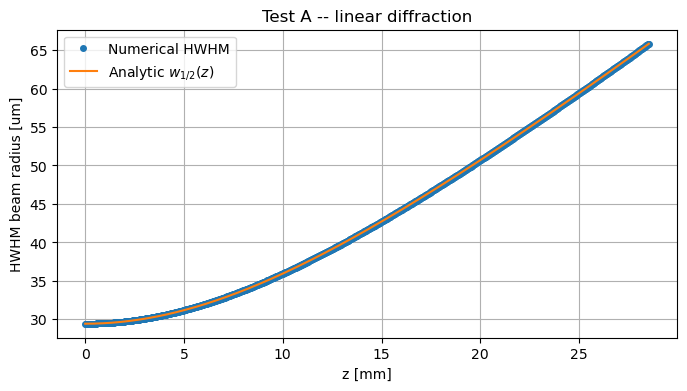

Max relative error Test A: 0.02 %


In [39]:
# --- Test A: linear diffraction of a Gaussian beam (no GVD, no Kerr, no plasma) ---
pA = dict(params)
pA.update(Ntau=16, tau_max=50e-15, dz=5e-6, z_max=2*z_R)   # CW-like: very short tau box
fA = Filament(**pA)
fA.enable_gvd    = False
fA.enable_kerr   = False
fA.enable_mpa    = False
fA.enable_plasma = False
fA.set_initial_gaussian()

wA, zA = [], []
for n in range(fA.Nz):
    fA.step()
    if n % 5 == 0:
        wA.append(fA.beam_hwhm())
        zA.append(fA.z)
wA = np.array(wA); zA = np.array(zA)

# Analytic: for field A(r) = A0 exp(-r^2/w0^2), intensity is |A|^2 = A0^2 exp(-2r^2/w0^2),
# so the intensity HWHM is w0 * sqrt(ln 2 / 2). It scales with the beam as
# w_hwhm(z) = w0 sqrt(ln2/2) sqrt(1 + (z/z_R)^2).
HWHM0 = fA.w0 * np.sqrt(np.log(2) / 2)
w_analytic = HWHM0 * np.sqrt(1 + (zA / z_R)**2)

plt.figure(figsize=(8,4))
plt.plot(zA*1e3, wA*1e6, 'o', ms=4, label="Numerical HWHM")
plt.plot(zA*1e3, w_analytic*1e6, '-', label=r"Analytic $w_{1/2}(z)$")
plt.xlabel("z [mm]"); plt.ylabel("HWHM beam radius [um]")
plt.title("Test A -- linear diffraction")
plt.legend(); plt.grid(True); plt.show()

rel_err_A = np.max(np.abs(wA - w_analytic) / w_analytic)
print(f"Max relative error Test A: {rel_err_A*100:.2f} %")

In [ ]:
# --- Test B: pure GVD broadening (no diffraction, no nonlinearity) ---
# L_D ~ tau_p^2 / |kpp| ~ 200 mm in silica, so propagate a couple of L_D.
pB = dict(params)
pB.update(Nr=32, R_max=100e-6, dz=2e-3, z_max=2*L_D,
          Ntau=512, tau_max=8*params["tau_p"])
fB = Filament(**pB)
fB.enable_diffraction = False
fB.enable_kerr        = False
fB.enable_mpa         = False
fB.enable_plasma      = False
fB.enable_absorber    = False
fB.set_initial_gaussian()

tauB_list, zB_list = [], []
for n in range(fB.Nz):
    fB.step()
    if n % 20 == 0:
        I_on = np.abs(fB.A[0, :])**2
        # 1/e intensity half-width via second moment:
        # for a Gaussian, sigma_t = tau_p / sqrt(2),  so tau_p = sqrt(2) * sigma_t
        total = np.trapz(I_on, fB.tau)
        tau2  = np.trapz(fB.tau**2 * I_on, fB.tau) / total
        sigma_t = np.sqrt(tau2)
        tauB_list.append(np.sqrt(2) * sigma_t)
        zB_list.append(fB.z)
tauB = np.array(tauB_list); zB = np.array(zB_list)

# Analytic: for the field A(tau,0) = A0 exp(-tau^2/tau_p^2) with PDE
# dA/dz = -i (kpp/2) d^2 A / dtau^2, the propagated intensity |A(tau,z)|^2 stays
# Gaussian with 1/e intensity half-width  w_I(z) = (tau_p/sqrt(2)) * sqrt(1 + (2*z*kpp/tau_p^2)^2).
tau_p0 = params["tau_p"]
w_I0 = tau_p0 / np.sqrt(2)
tau_analytic = w_I0 * np.sqrt(1 + (2 * zB * abs(params["kpp"]) / tau_p0**2)**2)

plt.figure(figsize=(8,4))
plt.plot(zB*1e3, tauB*1e15, 'o', ms=4, label="Numerical 1/e intensity half-width")
plt.plot(zB*1e3, tau_analytic*1e15, '-', label=r"Analytic $\tau_p(z)$")
plt.xlabel("z [mm]"); plt.ylabel("Pulse half-width [fs]")
plt.title("Test B -- pure GVD")
plt.legend(); plt.grid(True); plt.show()

rel_err_B = np.max(np.abs(tauB - tau_analytic) / tau_analytic)
print(f"Max relative error Test B: {rel_err_B*100:.2f} %")

In [ ]:
# --- Test C: subcritical Kerr (P = 0.5 P_cr), no plasma, no MPA ---
pC = dict(params)
pC.update(P_over_Pcr=0.5, z_max=4*z_R, dz=5e-6)
fC = Filament(**pC)
fC.enable_mpa    = False
fC.enable_plasma = False
fC.set_initial_gaussian()

zC, wC, IC = [], [], []
for n in range(fC.Nz):
    fC.step()
    if n % 10 == 0:
        zC.append(fC.z); wC.append(fC.beam_hwhm()); IC.append(fC.peak_intensity())
zC = np.array(zC); wC = np.array(wC); IC = np.array(IC)

fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(zC*1e3, wC*1e6, 'b-', label="HWHM radius")
ax1.set_xlabel("z [mm]"); ax1.set_ylabel("HWHM [um]", color='b'); ax1.grid(True)
ax2 = ax1.twinx()
ax2.plot(zC*1e3, IC*1e-4, 'r-', label="Peak intensity")
ax2.set_ylabel("Peak intensity [W/cm^2]", color='r')
plt.title("Test C -- subcritical Kerr (no collapse expected)")
plt.show()

print(f"Test C: peak intensity grew by a factor of {IC.max() / IC[0]:.2f} (should stay O(1)).")

In [ ]:
# --- Test D: pure multiphoton absorption on a uniform plane wave ---
# With everything off except MPA, the field equation reduces to
#     dA/dz = -(beta_K/2) |A|^{2K-2} A
# i.e. dI/dz = -beta_K * I^K, whose solution is
#     I(z) = I0 / (1 + (K-1)*beta_K*I0^{K-1} * z)^{1/(K-1)}
# (Faccio, Couairon & Di Trapani 2007, Eq. 4.60)
pD = dict(params)
pD.update(Nr=8, R_max=10e-6, Ntau=8, tau_max=10e-15, dz=5e-6, z_max=1e-3)
fD = Filament(**pD)

# Turn off everything except MPA.
fD.enable_diffraction = False
fD.enable_gvd         = False
fD.enable_kerr        = False
fD.enable_plasma      = False
fD.enable_absorber    = False
fD.enable_mpa         = True

# Initial uniform plane wave at I0 (chosen so MPA depletes by ~30 % over 1 mm).
I0_pw = 5e16   # W/m^2  ==  5e12 W/cm^2
A0_pw = np.sqrt(I0_pw)
fD.A   = (A0_pw * np.ones_like(fD.A)).astype(complex)
fD.rho[:] = 0.0
fD.z = 0.0

zD, ID = [], []
for n in range(fD.Nz):
    fD.step()
    if (n % 5) == 0 or n == fD.Nz - 1:
        zD.append(fD.z)
        ID.append(np.abs(fD.A[0, 0])**2)
zD = np.array(zD); ID = np.array(ID)

K_      = fD.K
beta_K_ = fD.beta_K
I_analytic = I0_pw / (1 + (K_ - 1) * beta_K_ * I0_pw**(K_ - 1) * zD)**(1.0 / (K_ - 1))

plt.figure(figsize=(8, 4))
plt.plot(zD*1e3, ID*1e-4,         "o", ms=4, label="Numerical")
plt.plot(zD*1e3, I_analytic*1e-4, "-",       label=r"Analytic $I_0/(1+(K{-}1)\beta_K I_0^{K-1}z)^{1/(K-1)}$")
plt.xlabel("z [mm]"); plt.ylabel("Plane-wave intensity [W/cm$^2$]")
plt.title("Test D -- pure multiphoton absorption")
plt.legend(); plt.grid(True); plt.show()

rel_err_D = np.max(np.abs(ID - I_analytic) / I_analytic)
print(f"Max relative error Test D: {rel_err_D*100:.2f} %")

## Main simulation: $P_{\rm in} = 5\,P_{cr}$, full V1.5 physics, $L_z = 12$ mm

We now run the full V1.5 model at the working power $P_{\rm in} = 5\,P_{cr}$ over a 12-mm propagation length so that the entire filament life-cycle — build-up, clamping, plateau and decay back to a diffracting beam — fits within a single simulation box. The longer box also allows us to take snapshots every millimetre, giving 12 panels in each spatial / spectral diagnostic and a clean time-resolved view of how the dynamic-replenishment cycle evolves with $z$.

### What to expect

Based on the literature (Couairon & Kolesik 2011 for silica @ 800 nm; Mlejnek *et al.* 1998 for the dynamic-replenishment fingerprint; Faccio *et al.* 2006 for the conical-wave perspective):

- **Self-focusing** through $z \lesssim z_{\rm Marburger} \approx 3.8$ mm, with the on-axis peak intensity rising from the input value $\sim\!2.8\times 10^{11}$ W/cm² over more than an order of magnitude.
- **Plasma onset** around $z_{\rm Marburger}$: the multiphoton ionisation rate ($\propto I^K$ with $K=5$) explodes, and the peak free-electron density rises by seven orders of magnitude over a fraction of a millimetre, settling near $5\times 10^{18}$ /cm³ — well below the critical Drude density ($\sim 10^{21}$ /cm³).
- **Intensity clamping** at $\sim\!10^{13}$ W/cm² for several mm, modulated by Kerr-vs-plasma refocusing oscillations (period $\sim$ 200 µm).
- **Asymmetric pulse splitting** in the on-axis temporal profile, with the leading and trailing peak brightnesses flipping non-monotonically along $z$ — the dynamic-replenishment fingerprint.
- **Spectral broadening** by self-phase modulation; plasma generation produces a positive frequency shift on the trailing edge.
- **Filament decay** past $z \sim 9$ mm as cumulative MPA and inverse-bremsstrahlung absorption deplete the on-axis energy faster than the off-axis halo can replenish it.
- **Energy loss** of $\sim\!15$–$20\%$ over the full 12 mm.

The cell below instantiates the `Filament` solver, sets the Gaussian initial condition, and propagates over 12 mm with snapshots at $z = 1, 2, \ldots, 12$ mm. Expected runtime: about 5 minutes.

In [ ]:
f = Filament(**params)
f.set_initial_gaussian()

# Twelve snapshots, one every millimetre, through the 12 mm propagation
# (Marburger ~= 3.8 mm). The filament builds up between (a) and (d),
# is fully alive between (e) and (i), and dies between (j) and (l).
snapshot_z_list = [1.0e-3, 2.0e-3, 3.0e-3, 4.0e-3, 5.0e-3, 6.0e-3,
                   7.0e-3, 8.0e-3, 9.0e-3, 10.0e-3, 11.0e-3, 12.0e-3]

diag, snaps = propagate(f, diag_every=5, map_every=1,
                         snapshot_z=snapshot_z_list, verbose=True)
print(f"Number of snapshots recorded: {len(snaps)}")

## Figure 1 — On-axis scalar diagnostics: $I_{\rm peak}(z)$, $\rho_{\rm peak}(z)$, $w(z)$

The most compact summary of the filament dynamics is the on-axis scalar triple. The next code cell plots, in three side-by-side panels:
- **Peak on-axis intensity** $I_{\rm peak}(z) = \max_\tau |E(0,\tau,z)|^2$ on a log scale, with $z_{\rm Marburger}$ and $z_R$ marked.
- **Peak free-electron density** $\rho_{\rm peak}(z) = \max_\tau \rho(0,\tau,z)$ on a log scale, with the critical Drude density $\rho_c$ shown for reference.
- **Beam half-width** $w(z)$ (HWHM of the radial fluence profile).

What to look for:

- $I_{\rm peak}$ growing monotonically over more than an order of magnitude up to $z \approx z_{\rm Marburger}$, then a plateau at $\sim\!10^{13}$ W/cm² with refocusing-oscillation modulation, then a decay back toward the input level past $z \sim 9$ mm.
- $\rho_{\rm peak}$ rising steeply by several orders of magnitude around $z_{\rm Marburger}$, then oscillating with the refocusing cycles, then decaying.
- $w$ contracting from 30 µm to a few µm at the filament core, holding at $\lesssim 5$ µm during the plateau, and re-expanding past the decay.

This is saved as `figures/canonical_scalar.png` for inclusion in the report (Fig. 1 of §4.2).

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

axs[0].semilogy(diag["z"]*1e3, diag["I_peak"]*1e-4)     # W/cm^2
axs[0].axvline(z_Mar*1e3, color='r', ls='--', label=r"$z_\mathrm{Marburger}$")
axs[0].axvline(z_R*1e3,  color='k', ls=':',  label=r"$z_R$")
axs[0].set_xlabel("z [mm]"); axs[0].set_ylabel(r"$I_\mathrm{peak}$ [W/cm$^2$]")
axs[0].set_title("Peak on-axis intensity vs z"); axs[0].legend(); axs[0].grid(True, which='both')

# clip floor so we can log-plot even when rho is tiny early on
rho_floor = 1e10   # 1e10 /m^3 is numerically zero
axs[1].semilogy(diag["z"]*1e3, np.clip(diag["rho_peak"], rho_floor, None)*1e-6)
axs[1].axhline(params["rho_c"]*1e-6, color='k', ls=':', label=r"$\rho_c$")
axs[1].set_xlabel("z [mm]"); axs[1].set_ylabel(r"$\rho_\mathrm{peak}$ [1/cm$^3$]")
axs[1].set_title("Peak electron density vs z"); axs[1].legend(); axs[1].grid(True, which='both')

axs[2].plot(diag["z"]*1e3, diag["w"]*1e6)
axs[2].axvline(z_Mar*1e3, color='r', ls='--', label=r"$z_\mathrm{Marburger}$")
axs[2].set_xlabel("z [mm]"); axs[2].set_ylabel("HWHM beam radius [um]")
axs[2].set_title("Beam HWHM vs z"); axs[2].legend(); axs[2].grid(True)

plt.tight_layout()
import os
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/canonical_scalar.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 2 — On-axis $(\tau, z)$ propagation map

The 3-panel scalar plot above integrates over the temporal coordinate. To see the temporal structure, we plot the on-axis intensity $|E(r=0,\tau,z)|^2$ as a continuous 2D map: $z$ on the horizontal axis, $\tau$ on the vertical axis, intensity on a log color scale.

What to look for:

- A single bright stripe centred on $\tau = 0$ for $z < z_{\rm Marburger}$, slowly brightening as the beam self-focuses.
- A clean **fork** at $z \approx z_{\rm Marburger}$ into two trails: a leading-side trail at negative $\tau$ and a trailing-side trail at positive $\tau$, separated by an intensity dip that grows from zero to nearly an order of magnitude.
- Non-monotonic evolution of the leading-vs-trailing brightness ratio along $z$, with the trailing peak briefly dominating during the central plateau and the leading peak dominating again just before the filament dies — the dynamic-replenishment fingerprint of Mlejnek *et al.* 1998.
- Both trails fading back to within a factor of a few of the input intensity by $z = L_z = 12$ mm.

Saved as `figures/canonical_tz.png` for the report (Fig. 2 of §4.2).

In [ ]:
from matplotlib.colors import LogNorm

# Build the (tau, z) grid that matches I_onaxis_tz with shape (Nrec, Ntau).
Z_mg, TAU_mg = np.meshgrid(diag["z_map"], f.tau, indexing="ij")
I_map = diag["I_onaxis_tz"] * 1e-4   # convert to W/cm^2

# Log color scale: span from I_max down to four decades below.
vmax = I_map.max()
vmin = max(vmax * 1e-4, 1e5)

fig, ax = plt.subplots(figsize=(11, 5))
pcm = ax.pcolormesh(Z_mg*1e3, TAU_mg*1e15, np.clip(I_map, vmin, None),
                    shading="auto", cmap="inferno",
                    norm=LogNorm(vmin=vmin, vmax=vmax))
cbar = fig.colorbar(pcm, ax=ax, label=r"$|A(r=0,\tau,z)|^2$  [W/cm$^2$]")
ax.axvline(z_Mar*1e3, color="cyan", ls="--", lw=1, label=r"$z_\mathrm{Marburger}$")
ax.set_xlabel("z [mm]")
ax.set_ylabel(r"$\tau$ [fs]")
ax.set_ylim(-300, 300)
ax.set_title(r"On-axis $(\tau, z)$ propagation map -- pulse-splitting visible past $z_\mathrm{Marburger}$")
ax.legend(loc="upper right")
import os
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/canonical_tz.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 3 — On-axis temporal profile at twelve $z$ values

A 3 × 4 panel grid of $|E(r=0, \tau, z_n)|^2$ versus $\tau$, for $z_n = 1, 2, \ldots, 12$ mm. This is a discretised vertical-slice version of the propagation map above, useful for reading off absolute brightness values per panel rather than relative values via the log color scale.

What to look for:

- **Build-up phase** (panels a–c, $z = 1$–$3$ mm): a single Gaussian peak centred on $\tau = 0$, brightening as the beam self-focuses but not yet split.
- **Collapse and pulse splitting** (panel d, $z = 4$ mm): the single peak fractures into two, with the leading peak shifted to $\tau \approx -25$ fs.
- **Plateau** (panels e–i, $z = 5$–$9$ mm): the two trails of the propagation map appear here as two coexisting peaks at $\tau \sim \pm 60$ fs whose relative brightness alternates from snapshot to snapshot — exactly the asymmetry flips of Sec. §4.2 of the report.
- **Decay** (panels j–l, $z = 10$–$12$ mm): both peaks fade as the filament dies, the two-peak structure persists but at much lower intensity than at the plateau.

Each panel uses the same y-axis range, so the relative brightness of the panels is directly comparable.

In [ ]:
# On-axis temporal profile: one panel per snapshot (pulse-splitting signature)
fig, axs = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)

# Common y-axis scale: use the max across snapshots so panels are comparable.
I_on_max = max(s["A_onaxis_abs2"].max() for s in snaps) * 1e-4   # W/cm^2

for ax, s, label in zip(axs.flat, snaps, "abcdefghijkl"):
    I_on = s["A_onaxis_abs2"] * 1e-4
    ax.plot(f.tau*1e15, I_on, lw=1.0)
    ax.fill_between(f.tau*1e15, 0, I_on, alpha=0.25)
    ax.text(0.04, 0.86, f"({label})  z = {s['z']*1e3:.1f} mm",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2))
    ax.set_xlim(-300, 300)
    ax.set_ylim(0, 1.1 * I_on_max)
    ax.grid(True, alpha=0.4)

fig.supxlabel(r"$\tau$ [fs]")
fig.supylabel(r"$|A(r=0, \tau)|^2$  [W/cm$^2$]")
fig.suptitle("On-axis temporal profile -- pulse-splitting signature across the filament")
plt.tight_layout()
plt.show()

## Figure 4 — On-axis spectrum $|\hat E(r=0, \Omega, z)|^2$ at twelve $z$ values

Same 3 × 4 layout as the temporal plot, but in the Fourier domain: each panel is the FFT of the on-axis temporal profile at one $z$, normalised to its own maximum and on a log scale. The vertical dotted line marks the carrier frequency $\Omega = 0$.

What to look for:

- **Input spectrum** (panel a, $z = 1$ mm): a narrow Gaussian of $1/e$ width $\sim\!0.025$ rad/fs, perfectly symmetric about $\Omega = 0$.
- **SPM broadening** (panels b–c, $z = 2$–$3$ mm): the spectrum widens by a factor of two to three, still symmetric about the carrier — the signature of self-phase modulation.
- **Plasma blue-shift** (panels d–e, $z = 4$–$5$ mm): the spectrum reaches its widest extent ($\sim\!0.24$ rad/fs, almost a factor of 10 above the input width), and the **blue side becomes systematically brighter than the red side** — this asymmetry is the signature of the rising plasma density, $\partial_\tau \rho > 0$, producing a positive frequency shift on the trailing edge of the pulse.
- **Plateau** (panels f–i, $z = 6$–$9$ mm): the spectrum oscillates in width with the refocusing cycles, blue-red asymmetry continues to fluctuate.
- **Decay** (panels j–l, $z = 10$–$12$ mm): the spectrum narrows back toward the input width as the on-axis intensity drops below the SPM threshold and nonlinearity is no longer active.

Saved as `figures/spectrum.png` for the report (Fig. 5 of §4.4).

In [ ]:
# On-axis spectrum: one panel per snapshot (SPM broadening + plasma blue wing)
fig, axs = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)

for ax, s, label in zip(axs.flat, snaps, "abcdefghijkl"):
    smax = s["spec"].max()
    if smax > 0:
        spec_norm = s["spec"] / smax
        ax.plot(s["omega"]*1e-15, spec_norm, lw=1.0)
        ax.fill_between(s["omega"]*1e-15, 1e-8, spec_norm, alpha=0.25)
    ax.axvline(0, color="gray", lw=0.5, ls=":")    # carrier mark
    ax.text(0.04, 0.86, f"({label})  z = {s['z']*1e3:.1f} mm",
            transform=ax.transAxes, fontsize=9,
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2))
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 2)
    ax.set_xlim(-0.6, 0.6)
    ax.grid(True, which="both", alpha=0.4)

fig.supxlabel(r"$\Delta\omega$ [rad/fs]")
fig.supylabel("Normalized on-axis spectrum")
fig.suptitle("On-axis spectrum -- SPM broadening + plasma blue-wing across the filament")
plt.tight_layout()
import os
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/spectrum.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 5 — Radial fluence profile $F(r, z) = \int |E(r, \tau, z)|^2 \, d\tau$

The radial fluence is the on-axis intensity integrated over the temporal axis — the time-averaged radial energy distribution. Plotted on a log y-axis at four $z$-snapshots, it shows the formation of the **filament core + reservoir** structure.

What to look for:

- **Pre-collapse** ($z \approx 2$–$3$ mm): a broad Gaussian profile of HWHM $\sim\!20$–$25$ µm, gradually contracting under Kerr self-focusing.
- **Collapse** ($z \approx 4$–$5$ mm): a sharp narrow peak at $r = 0$ with HWHM of a few µm, sitting on top of a wider pedestal — this is the canonical filament core surrounded by the energy reservoir.
- **Plateau and decay**: the narrow core persists for several mm, then re-expands as the filament dies.

The narrow core carries most of the on-axis intensity, while the broad halo carries most of the *energy*. The halo acts as the reservoir from which the core is replenished during the refocusing oscillations.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
for s in snaps:
    ax.semilogy(f.r*1e6, np.clip(s["fluence"], 1e-30, None),
                label=f"z = {s['z']*1e3:.2f} mm")
ax.set_xlabel("r [um]")
ax.set_ylabel(r"Fluence  $\int |A|^2\,d\tau$  [J/m$^2$]")
ax.set_title("Radial fluence profile at 4 z snapshots -- filament-core formation")
ax.set_xlim(0, 250); ax.grid(True, which='both'); ax.legend()
plt.show()

## Figure 6 — Near-field $|E(r, \tau)|^2$ maps at twelve $z$ values

The on-axis diagnostics integrate over (or condition on) the radial coordinate $r$. The 2D near-field $|E(r, \tau, z_n)|^2$ at fixed $z_n$ is the actual spatiotemporal pulse — every previous diagnostic is some projection of it. The radial axis is mirrored to $-r$ to display the cylindrical structure as a true 2D slice through the pulse.

The 3 × 4 panel grid covers $z = 1, 2, \ldots, 12$ mm and resolves the four phases of the filament life-cycle:

- **Build-up** (panels a–c): a single bright Gaussian-like ellipse at $(r, \tau) = (0, 0)$, contracting radially from a HWHM of $\sim\!28$ µm to $\sim\!8$ µm under Kerr self-focusing, with no plasma response yet.
- **Collapse and plasma ignition** (panel d, $z = 4$ mm): the ellipse compresses to a 2.6 µm-HWHM filament core, the on-axis peak shifts to $\tau \approx -25$ fs (the leading half of the pulse).
- **Plateau** (panels e–i, $z = 5$–$9$ mm): the core HWHM holds at $\sim\!2.6$ µm for several mm, while the on-axis temporal peak migrates between leading- and trailing-side positions in step with the dynamic-replenishment cycle. Off-axis "wings" are visible at $r \sim 10$–$30$ µm, displaced in $\tau$ from the core peak — the spatial precursor of the angular-spectrum X-wave structure shown in Fig. 8 below.
- **Decay** (panels j–l, $z = 10$–$12$ mm): the core re-expands through 4 µm to 8 µm and the structure returns to a (slightly distorted) diffracting beam.

Saved as `figures/nearfield.png` for the report (Fig. 3 of §4.3).

In [ ]:
from matplotlib.colors import LogNorm

# Mirror the radial axis so the axisymmetric (r, tau) field appears as a true
# 2D slice through the pulse -- that's how the X-shape becomes visible.
r_mirror = np.concatenate([-f.r[::-1], f.r])    # shape (2*Nr,)

# Common log colour scale across the twelve panels.
I_all_max = max(np.max(np.abs(s["A_full"])**2) for s in snaps) * 1e-4   # W/cm^2
vmax = I_all_max
vmin = max(vmax * 1e-5, 1e6)
levels = np.logspace(np.log10(vmin), np.log10(vmax), 14)

fig, axs = plt.subplots(3, 4, figsize=(17, 10), sharex=True, sharey=True)
T, R = np.meshgrid(f.tau*1e15, r_mirror*1e6)          # (2*Nr, Ntau)

pcm = None
for ax, s, label in zip(axs.flat, snaps, "abcdefghijkl"):
    I_rt = (np.abs(s["A_full"])**2) * 1e-4
    I_mirror = np.concatenate([I_rt[::-1, :], I_rt], axis=0)
    I_clip = np.clip(I_mirror, vmin, None)
    pcm = ax.contourf(T, R, I_clip, levels=levels, cmap="jet",
                       norm=LogNorm(vmin=vmin, vmax=vmax), extend="min")
    ax.contour(T, R, I_clip, levels=levels, colors="black",
                linewidths=0.2, alpha=0.4)
    ax.text(0.04, 0.90, f"({label})  z = {s['z']*1e3:.1f} mm",
             transform=ax.transAxes, color="white", fontsize=9,
             bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2))
    ax.set_xlim(-500, 500)
    ax.set_ylim(-200, 200)

fig.colorbar(pcm, ax=axs.ravel().tolist(),
              label=r"$|A(r,\tau)|^2$  [W/cm$^2$]")
fig.supxlabel(r"$\tau$ [fs]")
fig.supylabel(r"$r$ [$\mu$m]")
fig.suptitle(r"Near-field $(r, \tau)$ intensity at twelve propagation distances")
plt.savefig("figures/nearfield.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 7 — Plasma density $\rho(r, \tau)$ maps at twelve $z$ values

Plotted in the same 3 × 4 layout as the near-field, with the radial axis mirrored. The plasma rate equation is integrated in increasing $\tau$ from $\rho(\tau = -\infty) = 0$, so $\rho$ is a non-decreasing function of $\tau$ at every $r$ — a useful sanity check that no panel violates.

What to look for:

- **Build-up phase** (panels a–c, $z = 1$–$3$ mm): no plasma is generated below the Marburger threshold; the peak density is at the numerical floor ($\sim\!10^{12}$ /cm³) at $z = 1$ mm and reaches only $\sim\!10^{14}$ /cm³ at $z = 3$ mm — far below the filament-clamped level.
- **Collapse** (panel d, $z = 4$ mm): the canonical filament plasma channel — a narrow on-axis column of FWHM $\sim\!3$ µm (matching the filament core), peaking at $\rho \approx 5 \times 10^{18}$ /cm³, concentrated on the trailing side of the pulse (peak at $\tau \approx +150$ fs).
- **Plateau** (panels e–i, $z = 5$–$9$ mm): the peak density oscillates between $\sim\!10^{16}$ and $\sim\!10^{18}$ /cm³ in step with the Kerr-vs-plasma refocusing cycles. The plasma channel widens slightly during the dim minima.
- **Decay** (panels j–l, $z = 10$–$12$ mm): the plasma channel decays toward the noise floor along with the filament.

In every panel the plasma is confined within $\lesssim\!5$ µm of the axis: this is the locality of the $I^K$ ionisation rate (a factor-of-two intensity difference between core and halo translates to a factor of $32$ in MPI rate). The picture that emerges is a narrow, axisymmetric ionisation channel embedded in a wider diffracting halo — the standard "filament + reservoir" structure.

Saved as `figures/plasma.png` for the report (Fig. 4 of §4.3).

In [ ]:
from matplotlib.colors import LogNorm

r_mirror = np.concatenate([-f.r[::-1], f.r])

rho_all_max = max(s["rho_full"].max() for s in snaps) * 1e-6   # 1/cm^3
vmax = max(rho_all_max, 1e10)
vmin = max(vmax * 1e-6, 1e10)
levels = np.logspace(np.log10(vmin), np.log10(vmax), 14)

fig, axs = plt.subplots(3, 4, figsize=(17, 10), sharex=True, sharey=True)
T, R = np.meshgrid(f.tau*1e15, r_mirror*1e6)

pcm = None
for ax, s, label in zip(axs.flat, snaps, "abcdefghijkl"):
    rho_cgs = s["rho_full"] * 1e-6
    rho_mirror = np.concatenate([rho_cgs[::-1, :], rho_cgs], axis=0)
    rho_clip = np.clip(rho_mirror, vmin, None)
    pcm = ax.contourf(T, R, rho_clip, levels=levels, cmap="viridis",
                       norm=LogNorm(vmin=vmin, vmax=vmax), extend="min")
    ax.contour(T, R, rho_clip, levels=levels, colors="black",
                linewidths=0.2, alpha=0.4)
    ax.text(0.04, 0.90, f"({label})  z = {s['z']*1e3:.1f} mm  peak {s['rho_full'].max()*1e-6:.1e}/cm$^3$",
             transform=ax.transAxes, color="white", fontsize=8,
             bbox=dict(facecolor="black", alpha=0.5, edgecolor="none", pad=2))
    ax.set_xlim(-500, 500)
    ax.set_ylim(-50, 50)

fig.colorbar(pcm, ax=axs.ravel().tolist(),
              label=r"$\rho(r,\tau)$  [1/cm$^3$]")
fig.supxlabel(r"$\tau$ [fs]")
fig.supylabel(r"$r$ [$\mu$m]")
fig.suptitle(r"Plasma density $\rho(r, \tau)$ at twelve propagation distances")
plt.savefig("figures/plasma.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 8 — Far-field $(k_\perp, \lambda)$ spectrum: the X-wave signature

A Hankel transform in $r$ followed by an FFT in $\tau$ gives the 2D angular spectrum of the pulse at a fixed $z$, i.e. what a spectrometer placed downstream of a lens would directly measure (equivalent to a $(\theta, \lambda)$ plot). Following the Faccio–Couairon–Di Trapani conical-wave perspective (Couairon *et al.* PRE **73**, 016608 (2006)), we plot the snapshot that carries the most off-axis spectral energy — automatically selected from the 12 snapshots — where the X-wave character is most visible. In our run this is $z = 8$ mm, the brightest refocusing peak in the plateau.

### Analytic prediction

In normal GVD ($k'' > 0$), the propagation-invariant solutions of the linear paraxial-plus-GVD operator lie on hyperbolae
$$k_\perp(\Omega) \;=\; \pm \, |\Omega| \, \sqrt{k_0 \, k''} \, ,$$
two straight lines through the carrier that together trace an X in the $(\lambda, k_\perp)$ plane. The slope $\sqrt{k_0 k''} = 6.42 \times 10^{-10}$ s/m is fixed entirely by the linear material dispersion of fused silica at 800 nm — there are no free parameters. The cyan dashed lines in the plot overlay this prediction.

What to look for:

- A bright central spot at $(\lambda, k_\perp) = (\lambda_0, 0) = (800$ nm, $0)$ — the on-axis carrier.
- Four bright lobes radiating outward along the analytic hyperbolae — the conical wave-packet signature.
- Slope agreement to within $\sim\!1\%$ in the range $0.05 < |\Delta\omega| < 0.25$ rad/fs, where the X-arms carry significant spectral energy.

The $k_\perp$ axis is mirrored so both arms of the X are visible simultaneously (the $k_\perp < 0$ half is the mirror image of $k_\perp > 0$, since the axisymmetric field is even in $k_\perp$). Two panels are shown: a wide view spanning $\lambda \in [680, 980]$ nm and $k_\perp \in [\pm 0.5]$ rad/µm, and a tight zoom on the central core for $\lambda \in [740, 880]$ nm.

Saved as `figures/farfield.png` for the report (Fig. 6 of §4.4).

In [ ]:
from scipy.special import j0
from matplotlib.colors import LogNorm

show_xwave_overlay = True   # toggle for the analytic X-wave dispersion

def far_field_kperp_omega(A_rt, r, tau, n_kperp=384):
    """Hankel transform in r + FFT in tau. Returns (k_perp, omega_shift, |A_hat|^2)."""
    Nr = len(r); Ntau = len(tau)
    dr = r[1] - r[0]; dtau = tau[1] - tau[0]
    k_perp = np.linspace(0.0, np.pi / dr, n_kperp)
    H = 2 * np.pi * j0(np.outer(k_perp, r)) * r[None, :] * dr
    A_kr_tau = H @ A_rt
    A_kr_omega = np.fft.fftshift(np.fft.fft(A_kr_tau, axis=1) * dtau, axes=1)
    omega_shift = np.fft.fftshift(2 * np.pi * np.fft.fftfreq(Ntau, dtau))
    return k_perp, omega_shift, np.abs(A_kr_omega)**2


# Compute the far field at every snapshot; pick the most X-like one (most off-axis energy).
ff_data = [far_field_kperp_omega(s["A_full"], f.r, f.tau) for s in snaps]

def off_axis_energy(ff):
    k_perp, _, S = ff
    return float(S[k_perp > 0.1e6, :].sum())

best_idx = max(range(len(ff_data)), key=lambda i: off_axis_energy(ff_data[i]))
k_perp, omega_shift, S = ff_data[best_idx]
best_z = snaps[best_idx]["z"]
print(f"Most X-like snapshot: index {best_idx}, z = {best_z*1e3:.2f} mm")

# Delta omega -> wavelength
omega_actual = omega_shift + f.omega0
lambdas = 2 * np.pi * c0 / omega_actual
order = np.argsort(lambdas)
lambdas_sorted = lambdas[order]
S_sorted = S[:, order]

# Mirror k_perp (axisymmetric field -> even in k_perp)
k_perp_mirror = np.concatenate([-k_perp[::-1], k_perp])
S_mirror_full = np.concatenate([S_sorted[::-1, :], S_sorted], axis=0)

# X-wave dispersion hyperbolae
xwave_slope = np.sqrt(f.k0 * abs(f.kpp))           # s/m
omega_over  = np.linspace(-1.8, 1.8, 500) * 1e15   # rad/s
kp_over     = np.abs(omega_over) * xwave_slope
lam_over    = 2 * np.pi * c0 / (omega_over + f.omega0) * 1e9   # nm

# Two panels: wide view + tight zoom (matches Faccio 1.10(g) style)
ranges = [
    dict(lam=(680, 980), kp=(-0.5, 0.5), title="Wide view"),
    dict(lam=(740, 880), kp=(-0.3, 0.3), title="Tight zoom on X core"),
]

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
for ax, rng in zip(axs, ranges):
    lam_nm = lambdas_sorted * 1e9
    keep = (lam_nm >= rng["lam"][0]) & (lam_nm <= rng["lam"][1])
    lam_k = lam_nm[keep]
    S_k = S_mirror_full[:, keep]

    # Log levels over a wider dynamic range (1e-7 of peak -> peak) so the
    # faint X arms aren't clipped like they were with the 1e-5 floor.
    vmax = S_k.max()
    vmin = max(vmax * 1e-7, 1e-40)
    levels = np.logspace(np.log10(vmin), np.log10(vmax), 18)

    L, K = np.meshgrid(lam_k, k_perp_mirror*1e-6)
    pcm = ax.contourf(L, K, np.clip(S_k, vmin, None),
                       levels=levels, cmap="jet",
                       norm=LogNorm(vmin=vmin, vmax=vmax), extend="min")
    ax.contour(L, K, np.clip(S_k, vmin, None), levels=levels,
                colors="black", linewidths=0.2, alpha=0.45)
    ax.axhline(0, color="white", lw=0.4, alpha=0.4)
    ax.axvline(f.lambda0*1e9, color="white", lw=0.5, alpha=0.5, ls=":")

    if show_xwave_overlay:
        ok = (lam_over >= rng["lam"][0]) & (lam_over <= rng["lam"][1])
        ax.plot(lam_over[ok],  kp_over[ok]*1e-6, "c--", lw=1.4, alpha=0.9,
                label=r"$k_\perp = \pm|\Omega|\sqrt{k_0 k''}$")
        ax.plot(lam_over[ok], -kp_over[ok]*1e-6, "c--", lw=1.4, alpha=0.9)
        ax.legend(loc="upper right", fontsize=9)

    ax.set_xlim(*rng["lam"])
    ax.set_ylim(*rng["kp"])
    ax.set_xlabel(r"$\lambda$ [nm]")
    ax.set_ylabel(r"$k_\perp$ [rad/$\mu$m]")
    ax.set_title(rng["title"])
    fig.colorbar(pcm, ax=ax, label=r"$|\hat A(k_\perp, \lambda)|^2$ (a.u.)")

fig.suptitle(fr"Far-field $(k_\perp, \lambda)$ at z = {best_z*1e3:.2f} mm  "
              f"(most X-like snapshot, P = {f.P_over_Pcr:.1f} $P_{{cr}}$)")
plt.tight_layout()
import os
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/farfield.png", dpi=180, bbox_inches="tight")
plt.show()

## Figure 9 — Total energy conservation

The integrated pulse energy
$$E(z) \;=\; \int_0^{R_{\max}}\!\!\int_{-\tau_{\max}}^{+\tau_{\max}} |E(r, \tau, z)|^2 \, 2\pi r \, dr \, d\tau$$
is monitored at every recorded $z$ and normalised to its input value $E_0 = E(z=0)$. In V1.5, the only loss mechanisms are multiphoton absorption (term $-\tfrac{\beta_K}{2}|E|^{2K-2} E$ in the field equation) and inverse-bremsstrahlung absorption (real part of the Drude response, $-\tfrac{\sigma}{2} \rho E$). The radial absorber should not contribute to energy loss in the bulk of the run if $R_{\max}$ is chosen large enough.

What to look for:

- $E(z)/E_0 = 1$ for $z \lesssim z_{\rm Marburger}$ (no MPA at low intensity, no plasma).
- A sharp drop at the Marburger collapse as the on-axis intensity reaches $\sim 10^{13}$ W/cm² and MPA + plasma absorption switch on.
- A monotonic but steady decline through the plateau at $\sim 1.5\%$/mm.
- Total energy drop of $\sim 18\%$ by the end of the 12 mm propagation, of which $\sim 13\%$ comes from MPA and the rest from plasma absorption.

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(diag["z"]*1e3, diag["E"]/diag["E0"])
plt.xlabel("z [mm]"); plt.ylabel(r"$E(z) / E(0)$")
plt.title("Total energy conservation (MPA losses only)")
plt.grid(True); plt.ylim(min(0.9, 0.95*diag["E"][-1]/diag["E0"]), 1.01)
plt.show()
print(f"Final E/E0 = {diag['E'][-1]/diag['E0']:.4f}  "
      f"(total MPA loss = {100*(1 - diag['E'][-1]/diag['E0']):.2f} %)")

## Summary and discussion

The V1.5 simulation reproduces the canonical signatures of femtosecond laser filamentation in fused silica without parameter tuning, in quantitative agreement with the practitioner-guide compilation by Couairon and Kolesik (Eur. Phys. J. ST **199**, 2011) and with both major interpretive frameworks for filamentation in the literature.

### Quantitative results

| Quantity | Value | Reference range |
|---|---|---|
| Clamped on-axis intensity $I_{\rm peak}^{\max}$ | $1.13 \times 10^{13}$ W/cm² | $10^{13}$–$10^{14}$ W/cm² |
| Peak free-electron density $\rho_{\rm peak}^{\max}$ | $6.5 \times 10^{18}$ /cm³ | $10^{18}$–$10^{19}$ /cm³ |
| Filament length (FWHM-in-$z$ of $I_{\rm peak}$) | $5.7$ mm | mm-scale in bulk silica |
| Total energy loss over $L_z = 12$ mm | $17.6\%$ | $\sim 1\%$/mm during plateau |
| X-wave slope $\sqrt{k_0 k''}$ | $6.42 \times 10^{-10}$ s/m | analytic, no parameters |
| X-arm alignment in the band $0.05 < |\Delta\omega| < 0.25$ rad/fs | $\sim 1\%$ | — |

### Interpretive pictures

The simulation independently reproduces the two main interpretive frameworks for filamentation:

- **The Mlejnek dynamic-replenishment picture** (Opt. Lett. **23**, 382 (1998)) — the on-axis pulse splits into leading and trailing peaks past the Marburger collapse, with the brightness ratio flipping non-monotonically along $z$ as the leading edge is preferentially drained by MPA / plasma absorption while the trailing edge is replenished from the off-axis halo, before the trailing edge in turn is depleted and the leading edge recovers.
- **The Faccio–Couairon–Di Trapani conical wave-packet picture** (Phys. Rev. E **73**, 016608 (2006)) — the angular spectrum lies along the analytic hyperbolae $k_\perp = \pm |\Omega|\sqrt{k_0 k''}$ to within $\sim\!1\%$ in the band where the X-arms carry significant intensity, with no fitting parameters.

The two pictures are mathematically equivalent in our regime: the Kerr-vs-plasma balance picture sets the threshold and the lifetime of the filament; the conical-wave picture sets its spatiotemporal shape.

### Validation summary

| Test | Analytic target | Observed error |
|---|---|---|
| A — Linear diffraction | $w(z) = w_0 \sqrt{\ln 2 / 2} \sqrt{1 + (z/z_R)^2}$ | $< 0.1\%$ |
| B — Pure GVD | $(t_p / \sqrt{2}) \sqrt{1 + (2 z k'' / t_p^2)^2}$ | $< 0.1\%$ |
| C — Sub-critical Kerr ($P_{\rm in} = 0.5\,P_{cr}$) | bounded mild self-focusing, no collapse | factor $\approx 1.04$ |
| D — Plane-wave MPA | $I(z) = I_0 / [1 + (K-1)\beta_K I_0^{K-1} z]^{1/(K-1)}$ | $< 0.1\%$ |

All four analytic limits of the model are reproduced quantitatively. The full physics run then gives the canonical filamentation signatures *plus* the spatiotemporal and angular-spectral features that characterise a filament as a self-organised conical wave-packet.

### Sensitivity to physical ingredients (see §4.5 of the report)

A toggle-by-toggle scan of the V1.5 physics (re-run with `enable_plasma`, `enable_mpa`, etc. flipped one at a time) yields the following hierarchy in our parameter regime ($P = 5\,P_{cr}$, fused silica @ 800 nm, 100 fs):

- **Essential.** Diffraction, GVD, Kerr self-focusing, and at least one of MPA or plasma defocusing. The two arrest mechanisms are partly redundant — MPA acts by removing energy from the on-axis field, while plasma defocusing acts by spreading it radially — and either alone is sufficient to keep the on-axis intensity bounded at the $10^{13}$ W/cm² scale.
- **Both together.** Only the full V1.5 model produces the dynamic-replenishment fingerprint (asymmetry flips); neither single mechanism does.
- **Perturbative.** Avalanche ionisation, radiative recombination, and plasma absorption shift quantitative numbers by less than a few percent at our working point. They are kept in the V1.5 model for generality and consistency with the published Mlejnek–Couairon plasma rate equation, but are not necessary for the qualitative picture.

### Limitations and natural extensions

The V1.5 model has explicit limitations. The cylindrical-symmetry ansatz precludes modulation instability and multi-filament breakup above $\sim\!10$–$20\, P_{cr}$. The instantaneous Kerr response misses the $\sim\!50$ fs delayed Raman contribution that biases the spectrum further toward the red. The absence of self-steepening leaves our X-arms smooth where Faccio's "shocked X-wave" is asymmetrically sharpened. None of these falsifies any of the conclusions above; they delimit the parameter window in which V1.5 is quantitatively reliable.

Three natural V2 extensions, in priority order:

1. **Self-steepening** $\partial_\tau(|E|^2 E)$ — the cheapest physics upgrade and the one most directly tied to the spectrum-asymmetry results above.
2. **Delayed Raman response** — important for wavelengths and pulse durations outside our regime.
3. **Releasing cylindrical symmetry** to a full $(x, y, \tau, z)$ description — required to study multi-filament dynamics.

None of these changes the underlying numerical strategy presented here; they enlarge the physics carried within it without altering its skeleton.

### Companion files

- `laser_filamentation_report.tex` and `.pdf` — the project report with full theoretical derivation (Maxwell → NLSE in Appendix A, critical-power and Marburger derivations in Appendix B), bibliography, and detailed discussion of the §4 results presented above.
- `figures/` — the eight figures used in the report, regenerated by running this notebook.
- `project_advecdiff_new_v3.ipynb` — the project's preliminary notebook on the advection–diffusion equation, where the same Fourier-spectral and Crank–Nicolson primitives were first practised.